In [1]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

from data_loading import load_clean

df = load_clean()
df.shape

(668897, 13)

In [3]:
df.head()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimAmount
66,139.0,1,0.75,F,7,1,61,50,B12,'Regular',27000,R11,303.00
93,190.0,1,0.14,B,12,5,50,60,B12,'Diesel',56,R25,1981.84
199,414.0,1,0.14,E,4,0,36,85,B12,'Regular',4792,R11,1456.55
205,424.0,2,0.62,F,10,0,51,100,B12,'Regular',27000,R11,10834.00
223,463.0,1,0.31,A,5,0,45,50,B12,'Regular',12,R73,3986.67


In [4]:
df["age_group"] = pd.cut(df["DrivAge"], bins=[17, 25, 35, 45, 55, 65, 100])

modele_freq = smf.glm(
    "ClaimNb ~ BonusMalus + C(age_group)",
    data=df,
    family=sm.families.Poisson(),
    offset=np.log(df["Exposure"])
).fit()

print(modele_freq.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               668897
Model:                            GLM   Df Residuals:                   668890
Model Family:                 Poisson   Df Model:                            6
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.0801e+05
Date:                Thu, 12 Nov 2026   Deviance:                   1.6526e+05
Time:                        21:54:32   Pearson chi2:                 1.17e+06
No. Iterations:                     7   Pseudo R-squ. (CS):           0.008753
Covariance Type:            nonrobust                                         
                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------

In [5]:
pearson_ratio = (
    modele_freq.pearson_chi2 / modele_freq.df_resid
)

deviance_ratio = (
    modele_freq.deviance / modele_freq.df_resid
)

print("Rapport de Pearson :", pearson_ratio)
print("Rapport de déviance :", deviance_ratio)

Rapport de Pearson : 1.7510552143244247
Rapport de déviance : 0.24706761294047985


Rapport de Pearson plutot élevé

In [6]:
np.exp(modele_freq.params)

Intercept                                            0.012623
C(age_group)[T.Interval(25, 35, closed='right')]     0.882826
C(age_group)[T.Interval(35, 45, closed='right')]     1.165986
C(age_group)[T.Interval(45, 55, closed='right')]     1.325992
C(age_group)[T.Interval(55, 65, closed='right')]     1.166788
C(age_group)[T.Interval(65, 100, closed='right')]    1.124260
BonusMalus                                           1.027593
dtype: float64

In [7]:
print(modele_freq.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               668897
Model:                            GLM   Df Residuals:                   668890
Model Family:                 Poisson   Df Model:                            6
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.0801e+05
Date:                Thu, 12 Nov 2026   Deviance:                   1.6526e+05
Time:                        21:54:32   Pearson chi2:                 1.17e+06
No. Iterations:                     7   Pseudo R-squ. (CS):           0.008753
Covariance Type:            nonrobust                                         
                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------

In [8]:
modele_freq_q = smf.glm(
    "ClaimNb ~ BonusMalus + C(age_group)",
    data=df,
    family=sm.families.Poisson(),
    offset=np.log(df["Exposure"])
).fit(scale="X2")

print(modele_freq_q.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               668897
Model:                            GLM   Df Residuals:                   668890
Model Family:                 Poisson   Df Model:                            6
Link Function:                    Log   Scale:                          1.7511
Method:                          IRLS   Log-Likelihood:                -61686.
Date:                Thu, 12 Nov 2026   Deviance:                   1.6526e+05
Time:                        21:54:35   Pearson chi2:                 1.17e+06
No. Iterations:                     9   Pseudo R-squ. (CS):           0.005008
Covariance Type:            nonrobust                                         
                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------

In [9]:
df["bm_group"] = pd.cut(df["BonusMalus"], bins=[49, 60, 80, 100, 120, 150, 250])

modele_freq2 = smf.glm(
    "ClaimNb ~ C(bm_group) + C(age_group)",
    data=df,
    family=sm.families.Poisson(),
    offset=np.log(df["Exposure"])
).fit()

print(modele_freq.deviance, modele_freq2.deviance)
np.exp(modele_freq2.params)

165261.05561975756 165006.78989846236


Intercept                                             0.050715
C(bm_group)[T.Interval(60, 80, closed='right')]       2.250219
C(bm_group)[T.Interval(80, 100, closed='right')]      2.917527
C(bm_group)[T.Interval(100, 120, closed='right')]     6.262659
C(bm_group)[T.Interval(120, 150, closed='right')]     8.872192
C(bm_group)[T.Interval(150, 250, closed='right')]    10.908046
C(age_group)[T.Interval(25, 35, closed='right')]      0.815778
C(age_group)[T.Interval(35, 45, closed='right')]      1.102422
C(age_group)[T.Interval(45, 55, closed='right')]      1.263936
C(age_group)[T.Interval(55, 65, closed='right')]      1.111628
C(age_group)[T.Interval(65, 100, closed='right')]     1.072728
dtype: float64

On obtient effectivement une déviance plus faible pour ce nouveau modèle mais ce modèle a plus de paramètres (5 pour le bonus-malus tandis qu'on en avait 1 pour modele_freq) donc la comparaison n'est pas équitable. on va regarder l'AIC qui elle pénalise le nombre de paramètres

In [10]:
print(modele_freq.aic, modele_freq2.aic)

216043.81548302455 215797.54976172937


Le fait que à bonus-malus égal, la tranche d'âge 18-25 ne soit pas la plus sinistrée m'intrigue, cela peut s'expliquer par le fait que les conducteurs jeunes ont eu peu de temps pour accumuler des bonus, de plus ils conduisent peut-être moins que les tranches plus "vieilles". Faisons quelques vérifications :

In [11]:
# Un modèle avec l'âge seul, sans bonus-malus
m_age = smf.glm(
    "ClaimNb ~ C(age_group)",
    data=df,
    family=sm.families.Poisson(),
    offset=np.log(df["Exposure"])
).fit()
np.exp(m_age.params)

Intercept                                            0.149441
C(age_group)[T.Interval(25, 35, closed='right')]     0.502771
C(age_group)[T.Interval(35, 45, closed='right')]     0.486546
C(age_group)[T.Interval(45, 55, closed='right')]     0.503740
C(age_group)[T.Interval(55, 65, closed='right')]     0.435035
C(age_group)[T.Interval(65, 100, closed='right')]    0.405852
dtype: float64

In [12]:
df.groupby("age_group", observed=True).apply(
    lambda g: np.average(g["BonusMalus"], weights=g["Exposure"])
)

age_group
(17, 25]     87.260877
(25, 35]     66.094467
(35, 45]     56.002900
(45, 55]     53.418128
(55, 65]     52.899283
(65, 100]    52.112566
dtype: float64

Le bonus-malus est beaucoup plus élevé pour les 18-25 ans, Un coefficient d’âge dans un modèle multivariable ne se lit pas comme l’effet de l’âge seul. Il mesure l’écart à profil de bonus-malus identique, et le bonus-malus est lui-même en partie une conséquence de l’âge. En tarification, cela pose aussi une question de colinéarité entre variables, et c’est une limite à mentionner honnêtement.

In [13]:
sev_df = df[df["ClaimNb"] > 0].copy()
sev_df["avg_cost"] = sev_df["ClaimAmount"] / sev_df["ClaimNb"]

print(sev_df["avg_cost"].describe())
print(sev_df["avg_cost"].quantile([0.5, 0.9, 0.99, 0.999]))
sev_df.head()

count    2.494400e+04
mean     2.221368e+03
std      2.899257e+04
min      1.000000e+00
25%      7.105550e+02
50%      1.172000e+03
75%      1.228080e+03
max      4.075401e+06
Name: avg_cost, dtype: float64
0.500      1172.00000
0.900      2738.08600
0.990     16327.00055
0.999    133304.83963
Name: avg_cost, dtype: float64


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimAmount,age_group,bm_group,avg_cost
66,139.0,1,0.75,F,7,1,61,50,B12,'Regular',27000,R11,303.00,"(55, 65]","(49, 60]",303.00
93,190.0,1,0.14,B,12,5,50,60,B12,'Diesel',56,R25,1981.84,"(45, 55]","(49, 60]",1981.84
199,414.0,1,0.14,E,4,0,36,85,B12,'Regular',4792,R11,1456.55,"(35, 45]","(80, 100]",1456.55
205,424.0,2,0.62,F,10,0,51,100,B12,'Regular',27000,R11,10834.00,"(45, 55]","(80, 100]",5417.00
223,463.0,1,0.31,A,5,0,45,50,B12,'Regular',12,R73,3986.67,"(35, 45]","(49, 60]",3986.67


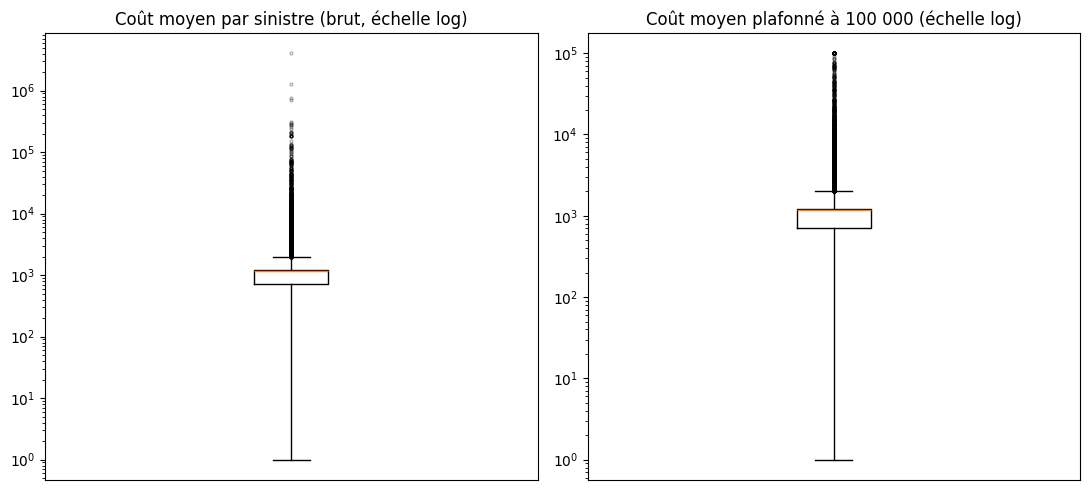

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# 1. Coût moyen brut, échelle log
axes[0].boxplot(sev_df["avg_cost"], showfliers=True,
                flierprops={"markersize": 2, "alpha": 0.3})
axes[0].set_yscale("log")
axes[0].set_title("Coût moyen par sinistre (brut, échelle log)")
axes[0].set_xticks([])

# 2. Coût moyen plafonné à 100 000 (variable utilisée dans le GLM Gamma)
axes[1].boxplot(sev_df["avg_cost"].clip(upper=100_000), showfliers=True,
                flierprops={"markersize": 2, "alpha": 0.3})
axes[1].set_yscale("log")
axes[1].set_title("Coût moyen plafonné à 100 000 (échelle log)")
axes[1].set_xticks([])

plt.tight_layout()
plt.show()

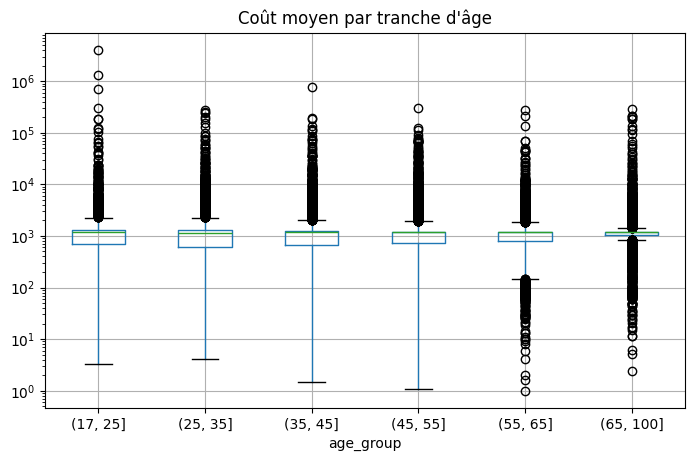

In [15]:
sev_df.boxplot(column="avg_cost", by="age_group", figsize=(8, 5))
plt.yscale("log")
plt.suptitle("")
plt.title("Coût moyen par tranche d'âge")
plt.show()

Figures du haut. La boîte est très étroite (environ 700 à 1 200) et la médiane est collée à sa borne haute. C’est la signature des montants répétés. La moustache du bas descend jusqu’à 1, et la masse de points au-dessus s’étale sur quatre ordres de grandeur. Sur la figure de droite, le plafonnement coupe bien la queue à 100 000, et la boîte reste identique, ce qui est normal : il ne touche que 39 sinistres.

Par tranche d’âge. Les boîtes sont presque alignées d’une tranche à l’autre, donc la sévérité varie peu avec l’âge. On peut s’attendre à des coefficients de sévérité proches de 1, à vérifier avec le GLM. C’est une différence importante avec la fréquence, où l’âge et le bonus-malus jouaient fortement.

Un détail à noter. Les tranches 55-65 et 65+ ont un amas de points entre 1 et 150, plus dense que dans les autres tranches.

In [16]:
petits = sev_df[sev_df["avg_cost"] < 150]
print(petits["age_group"].value_counts(normalize=True))
print(sev_df["age_group"].value_counts(normalize=True))

age_group
(35, 45]     0.250723
(45, 55]     0.241562
(25, 35]     0.236741
(55, 65]     0.116201
(17, 25]     0.094503
(65, 100]    0.060270
Name: proportion, dtype: float64
age_group
(45, 55]     0.249599
(35, 45]     0.240699
(25, 35]     0.195879
(55, 65]     0.125802
(65, 100]    0.098982
(17, 25]     0.089039
Name: proportion, dtype: float64


Une limite de la lecture

Avec 24 944 points et une échelle log, un boxplot ne montre pas la densité : on ne voit pas que les trois montants à 1 128, 1 172 et 1 204 pèsent 40 % des sinistres. Pour ça, un histogramme sur échelle log est plus parlant :

In [17]:
# Montants les plus fréquents
print(sev_df["avg_cost"].round(0).value_counts().head(10))

# Combien de sinistres au-dessus de 100 000, et quelle part du coût total ils représentent
gros = sev_df[sev_df["avg_cost"] > 100_000]
print(len(gros), gros["ClaimAmount"].sum() / sev_df["ClaimAmount"].sum())

# Combien de montants très faibles
print((sev_df["avg_cost"] < 100).sum())

avg_cost
1204.0    4418
1128.0    3616
1172.0    1932
602.0      380
1320.0     152
564.0      127
76.0       126
586.0       96
556.0       91
75.0        85
Name: count, dtype: int64
39 0.24109813187091175
1717


In [18]:
total = sev_df["ClaimAmount"].sum()
print(total)                               # coût total
print(gros["ClaimAmount"].sum())           # coût des 39 gros sinistres
print(gros["ClaimAmount"].sum() / total)   # = 0.241

59909216.5
14444000.180000002
0.24109813187091175


In [19]:
cap = 100_000
sev_df["avg_cost_cap"] = sev_df["avg_cost"].clip(upper=cap)

# Chargement grands sinistres : part au-dessus du plafond, par année d'exposition
excess = ((sev_df["avg_cost"] - cap).clip(lower=0) * sev_df["ClaimNb"]).sum()
charge_grands = excess / df["Exposure"].sum()
print(charge_grands)

28.098810706896764


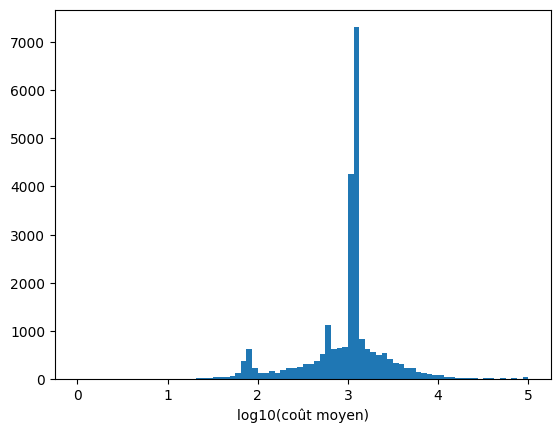

In [20]:
plt.hist(np.log10(sev_df["avg_cost_cap"]), bins=80)
plt.xlabel("log10(coût moyen)")
plt.show()

In [21]:
df["ClaimAmount"].sum() / df["Exposure"].sum()

np.float64(169.28577067181791)

In [22]:
modele_sev = smf.glm(
    "avg_cost_cap ~ C(age_group) + C(bm_group)",
    data=sev_df,
    family=sm.families.Gamma(link=sm.families.links.Log()),
    var_weights=sev_df["ClaimNb"]
).fit()

np.exp(modele_sev.params)

Intercept                                            2123.916883
C(age_group)[T.Interval(25, 35, closed='right')]        0.866172
C(age_group)[T.Interval(35, 45, closed='right')]        0.814044
C(age_group)[T.Interval(45, 55, closed='right')]        0.850707
C(age_group)[T.Interval(55, 65, closed='right')]        0.826940
C(age_group)[T.Interval(65, 100, closed='right')]       0.984894
C(bm_group)[T.Interval(60, 80, closed='right')]         1.027938
C(bm_group)[T.Interval(80, 100, closed='right')]        1.095177
C(bm_group)[T.Interval(100, 120, closed='right')]       1.019366
C(bm_group)[T.Interval(120, 150, closed='right')]       1.066464
C(bm_group)[T.Interval(150, 250, closed='right')]       1.210728
dtype: float64

In [23]:
df["freq_pred"] = modele_freq2.predict(df, offset=np.zeros(len(df)))
df["sev_pred"] = modele_sev.predict(df)
df["prime_pure"] = df["freq_pred"] * df["sev_pred"] + charge_grands

prime_moy = np.average(df["prime_pure"], weights=df["Exposure"])
reel = df["ClaimAmount"].sum() / df["Exposure"].sum()
print(prime_moy, reel)

169.26110849258475 169.28577067181791


In [24]:
df.tail()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimAmount,age_group,bm_group,freq_pred,sev_pred,prime_pure
678008,6114326.0,0,0.00274,E,4,0,54,50,B12,'Regular',3317,R93,0.0,"(45, 55]","(49, 60]",0.064100,1806.830859,143.917067
678009,6114327.0,0,0.00274,E,4,0,41,95,B12,'Regular',9850,R11,0.0,"(35, 45]","(80, 100]",0.163116,1893.518779,336.962537
678010,6114328.0,0,0.00274,D,6,2,45,50,B12,'Diesel',1323,R82,0.0,"(35, 45]","(49, 60]",0.055909,1728.961235,124.763448
678011,6114329.0,0,0.00274,B,4,0,60,50,B12,'Regular',95,R26,0.0,"(55, 65]","(49, 60]",0.056376,1756.351908,127.114796
678012,6114330.0,0,0.00274,B,7,6,29,54,B12,'Diesel',65,R72,0.0,"(25, 35]","(49, 60]",0.041372,1839.677081,104.209938


In [26]:
modele_freq3 = smf.glm(
    "ClaimNb ~ C(bm_group) * C(age_group)",
    data=df,
    family=sm.families.Poisson(),
    offset=np.log(df["Exposure"])
).fit()

print(modele_freq2.aic, modele_freq3.aic)
print(modele_freq2.deviance, modele_freq3.deviance)

215797.54976172937 215439.82359904802
165006.78989846236 164599.06373578106


In [30]:
df["prime_pure_v2"] = df["prime_pure"]   # on garde l'ancienne version pour comparer

df["freq_pred"] = modele_freq3.predict(df, offset=np.zeros(len(df)))
df["prime_pure"] = df["freq_pred"] * df["sev_pred"] + charge_grands

prime_moy = np.average(df["prime_pure"], weights=df["Exposure"])
reel = df["ClaimAmount"].sum() / df["Exposure"].sum()
print(prime_moy, reel)
print(df["prime_pure_v2"].nunique())

169.27765809523302 169.28577067181791
36


In [40]:
df["prime_pure_v2"] = (modele_freq2.predict(df, offset=np.zeros(len(df))) * df["sev_pred"]
                       + charge_grands)

In [41]:
comp = (df.assign(age=df["age_group"].astype(str), bm=df["bm_group"].astype(str))
          .groupby(["age", "bm"])[["prime_pure_v2", "prime_pure"]].first())

comp.loc[[("(65, 100]", "(60, 80]"), ("(17, 25]", "(60, 80]")]]

,,prime_pure_v2,prime_pure
age,bm,,
"(65, 100]","(60, 80]",291.333535,452.240461
"(17, 25]","(60, 80]",277.250468,184.555656


In [42]:
out = df.copy()
out["age_group"] = out["age_group"].astype(str)
out["bm_group"] = out["bm_group"].astype(str)
out.to_parquet("../data/portfolio_priced.parquet")